In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/prksh830/panther-preprocessed/preprocessing_log.csv
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_389.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_398.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_160.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_246.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_350.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_035.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_158.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_218.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_197.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_080.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_071.npy
/kaggle/input/datasets/prksh830/panther-preprocessed/labels/pancreas_199.npy
/

In [2]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 1 : IMPORT LIBRARIES
################################################################################

import os
import gc
import random
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from torch.amp import autocast
from torch.amp import GradScaler

warnings.filterwarnings("ignore")

In [3]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 2 : GLOBAL CONFIGURATION
################################################################################

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("="*80)
print("DEVICE :", DEVICE)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

print("="*80)

DEVICE : cuda
GPU : Tesla T4


In [4]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 3 : DATASET CONFIGURATION
################################################################################

ROOT = "/kaggle/input/datasets/prksh830/panther-preprocessed"

IMAGE_DIR = os.path.join(ROOT, "images")
LABEL_DIR = os.path.join(ROOT, "labels")

print("="*80)

print("Image Directory")
print(IMAGE_DIR)

print()

print("Label Directory")
print(LABEL_DIR)

print("="*80)

Image Directory
/kaggle/input/datasets/prksh830/panther-preprocessed/images

Label Directory
/kaggle/input/datasets/prksh830/panther-preprocessed/labels


In [5]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 4 : TRAIN VALIDATION SPLIT
################################################################################

image_files = sorted(

    [

        f

        for f in os.listdir(IMAGE_DIR)

        if f.endswith(".npy")

    ]

)

train_files, val_files = train_test_split(

    image_files,

    test_size=0.20,

    random_state=42,

    shuffle=True

)

print("="*80)

print("Training :", len(train_files))

print("Validation :", len(val_files))

print("="*80)

Training : 224
Validation : 57


In [6]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 5 : PANCREAS DATASET
################################################################################

class PancreasDataset(Dataset):

    def __init__(self,file_list):

        self.files=file_list

    def __len__(self):

        return len(self.files)

    def __getitem__(self,index):

        filename=self.files[index]

        image=np.load(

            os.path.join(

                IMAGE_DIR,

                filename

            )

        )

        mask=np.load(

            os.path.join(

                LABEL_DIR,

                filename

            )

        )

        image=torch.tensor(

            image,

            dtype=torch.float32

        )

        mask=torch.tensor(

            mask,

            dtype=torch.long

        )

        image=image.unsqueeze(0)

        return image,mask

In [7]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 6 : DATALOADER
################################################################################

BATCH_SIZE = 1

train_dataset = PancreasDataset(train_files)
val_dataset   = PancreasDataset(val_files)

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True,

    persistent_workers=True

)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True,

    persistent_workers=True

)

print("="*80)

print("Train Loader :", len(train_loader))

print("Validation Loader :", len(val_loader))

print("="*80)

Train Loader : 224
Validation Loader : 57


In [8]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 7 : VERIFY DATALOADER
################################################################################

images,masks=next(iter(train_loader))

print("="*80)

print("Images :",images.shape)

print("Masks  :",masks.shape)

print("Labels :",torch.unique(masks))

print("="*80)

Images : torch.Size([1, 1, 192, 192, 64])
Masks  : torch.Size([1, 192, 192, 64])
Labels : tensor([0, 1, 2])


In [9]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 8 : ConvBNReLU
################################################################################

class ConvBNReLU(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=kernel_size,
                stride=stride,
                padding=padding,
                bias=False
            ),

            nn.BatchNorm3d(out_channels),

            nn.ReLU(inplace=True)

        )

    def forward(self,x):

        return self.block(x)

In [10]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 9 : Residual Block
################################################################################

class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.conv1 = ConvBNReLU(
            in_channels,
            out_channels
        )

        self.conv2 = nn.Sequential(

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm3d(out_channels)

        )

        if in_channels != out_channels:

            self.shortcut = nn.Sequential(

                nn.Conv3d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False
                ),

                nn.BatchNorm3d(out_channels)

            )

        else:

            self.shortcut = nn.Identity()

        self.relu = nn.ReLU(inplace=True)

    def forward(self,x):

        identity = self.shortcut(x)

        out = self.conv1(x)

        out = self.conv2(out)

        out = out + identity

        out = self.relu(out)

        return out

In [11]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 10 : AIEM
################################################################################

class AIEM(nn.Module):

    def __init__(
        self,
        in_channels=1,
        out_channels=32
    ):

        super().__init__()

        self.stem = ConvBNReLU(
            in_channels,
            out_channels
        )

        self.depthwise = nn.Sequential(

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                groups=out_channels,
                bias=False
            ),

            nn.BatchNorm3d(out_channels),

            nn.ReLU(inplace=True)

        )

        self.pointwise = nn.Sequential(

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm3d(out_channels)

        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self,x):

        identity = self.stem(x)

        out = self.depthwise(identity)

        out = self.pointwise(out)

        out = out + identity

        out = self.relu(out)

        return out

In [12]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 11 : ACLB
################################################################################

class ACLB(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16
    ):

        super().__init__()

        reduced=max(channels//reduction,4)

        self.pool=nn.AdaptiveAvgPool3d(1)

        self.fc=nn.Sequential(

            nn.Conv3d(
                channels,
                reduced,
                kernel_size=1,
                bias=False
            ),

            nn.ReLU(inplace=True),

            nn.Conv3d(
                reduced,
                channels,
                kernel_size=1,
                bias=False
            ),

            nn.Sigmoid()

        )

    def forward(self,x):

        weight=self.pool(x)

        weight=self.fc(weight)

        return x*weight+x

In [13]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 12 : EncoderStage
################################################################################

class EncoderStage(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.res1=ResidualBlock(
            in_channels,
            out_channels
        )

        self.res2=ResidualBlock(
            out_channels,
            out_channels
        )

        self.aclb=ACLB(
            out_channels
        )

        self.pool=nn.MaxPool3d(2)

    def forward(self,x):

        x=self.res1(x)

        x=self.res2(x)

        skip=self.aclb(x)

        down=self.pool(skip)

        return skip,down

In [14]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 13 : PANTHER Encoder
################################################################################

from torch.utils.checkpoint import checkpoint

class PANTHEREncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.aiem = AIEM(1,32)

        self.encoder1 = EncoderStage(32,32)

        self.encoder2 = EncoderStage(32,48)

        self.encoder3 = EncoderStage(48,96)

        self.encoder4 = EncoderStage(96,192)

        self.bottleneck = nn.Sequential(

            ResidualBlock(192,384),

            ResidualBlock(384,384)

        )

    def forward(self,x):

        x=self.aiem(x)

        s1,x=self.encoder1(x)

        s2,x=self.encoder2(x)

        s3,x=self.encoder3(x)

        s4,x=self.encoder4(x)

        if self.training:

            x=checkpoint(
                self.bottleneck,
                x,
                use_reentrant=False
            )

        else:

            x=self.bottleneck(x)

        return s1,s2,s3,s4,x

In [15]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 14 : Cross Scale Feature Aggregation (CSFA)
################################################################################

class CSFA(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.conv1 = ConvBNReLU(
            channels,
            channels,
            kernel_size=1,
            padding=0
        )

        self.conv3 = ConvBNReLU(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        self.attention = ACLB(channels)

    def forward(self, x):

        identity = x

        x = self.conv1(x)

        x = self.conv3(x)

        x = self.attention(x)

        return x + identity

In [16]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 15 : Decoder Stage
################################################################################

class DecoderStage(nn.Module):

    def __init__(self,
                 in_channels,
                 skip_channels,
                 out_channels):

        super().__init__()

        self.up = nn.ConvTranspose3d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        self.refine = nn.Sequential(

            ResidualBlock(
                out_channels + skip_channels,
                out_channels
            ),

            ResidualBlock(
                out_channels,
                out_channels
            )

        )

        self.csfa = CSFA(out_channels)

    def forward(self, x, skip):

        x = self.up(x)

        if x.shape[2:] != skip.shape[2:]:

            x = F.interpolate(
                x,
                size=skip.shape[2:],
                mode="trilinear",
                align_corners=False
            )

        x = torch.cat([x, skip], dim=1)

        x = self.refine(x)

        x = self.csfa(x)

        return x

In [17]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 16 : Decoder
################################################################################

class PANTHERDecoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.decoder4 = DecoderStage(384,192,192)

        self.decoder3 = DecoderStage(192,96,96)

        self.decoder2 = DecoderStage(96,48,48)

        self.decoder1 = DecoderStage(48,32,32)

    def forward(self,
                bottle,
                s4,
                s3,
                s2,
                s1):

        x = self.decoder4(bottle,s4)

        x = self.decoder3(x,s3)

        x = self.decoder2(x,s2)

        x = self.decoder1(x,s1)

        return x

In [18]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 17 : Segmentation Head
################################################################################

class SegmentationHead(nn.Module):

    def __init__(self):

        super().__init__()

        self.head = nn.Sequential(

            ConvBNReLU(
                32,
                32
            ),

            nn.Conv3d(
                32,
                3,
                kernel_size=1
            )

        )

    def forward(self,x):

        return self.head(x)

In [19]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 18 : Complete PANTHER-Net
################################################################################

class PANTHERNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.encoder = PANTHEREncoder()

        self.decoder = PANTHERDecoder()

        self.segmentation_head = SegmentationHead()

    def forward(self,x):

        s1,s2,s3,s4,b = self.encoder(x)

        x = self.decoder(
            b,
            s4,
            s3,
            s2,
            s1
        )

        return self.segmentation_head(x)

In [20]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 19 : Model Initialization
################################################################################

model = PANTHERNet().to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("="*80)

print(f"Total Parameters : {total_params:,}")

print(f"Trainable Params : {trainable_params:,}")

print("="*80)

Total Parameters : 27,721,427
Trainable Params : 27,721,427


In [21]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 20 : Forward Verification
################################################################################

model.eval()

images, masks = next(iter(train_loader))

images = images.to(DEVICE)

with torch.no_grad():

    outputs = model(images)

print("="*80)

print("Input :", images.shape)

print("Output:", outputs.shape)

print("="*80)

Input : torch.Size([1, 1, 192, 192, 64])
Output: torch.Size([1, 3, 192, 192, 64])


In [22]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 21 : COMPUTE CLASS WEIGHTS
################################################################################

print("="*80)
print("Computing Class Weights...")
print("="*80)

num_classes = 3

class_counts = torch.zeros(num_classes)

for _, mask in train_loader:

    mask = mask.view(-1)

    class_counts += torch.bincount(
        mask,
        minlength=num_classes
    ).float()

print("Voxel Counts")

for i in range(num_classes):

    print(f"Class {i} : {int(class_counts[i])}")

weights = class_counts.sum() / (
    num_classes * class_counts
)

weights = weights / weights.mean()

CLASS_WEIGHTS = weights.to(DEVICE)

print("="*80)

print("Class Weights")

print(CLASS_WEIGHTS)

print("="*80)

Computing Class Weights...
Voxel Counts
Class 0 : 507078752
Class 1 : 18849436
Class 2 : 2554320
Class Weights
tensor([0.0132, 0.3564, 2.6303], device='cuda:0')


In [23]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 22 : FOREGROUND DICE LOSS
################################################################################

class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-5):

        super().__init__()

        self.smooth = smooth

    def forward(self, prediction, target):

        prediction = torch.softmax(prediction, dim=1)

        target = F.one_hot(
            target,
            num_classes=3
        ).permute(0,4,1,2,3).float()

        total_loss = 0

        classes = [1,2]

        for cls in classes:

            pred = prediction[:, cls]

            gt = target[:, cls]

            intersection = (pred * gt).sum()

            denominator = pred.sum() + gt.sum()

            dice = (

                2 * intersection + self.smooth

            ) / (

                denominator + self.smooth

            )

            total_loss += (1 - dice)

        return total_loss / len(classes)

In [24]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 23 : HYBRID LOSS
################################################################################

class HybridLoss(nn.Module):

    def __init__(self):

        super().__init__()

        self.ce = nn.CrossEntropyLoss(
            weight=CLASS_WEIGHTS
        )

        self.dice = DiceLoss()

    def forward(
        self,
        prediction,
        target
    ):

        ce_loss = self.ce(
            prediction,
            target
        )

        dice_loss = self.dice(
            prediction,
            target
        )

        total_loss = (

            0.50 * ce_loss

            +

            0.50 * dice_loss

        )

        return total_loss

In [25]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 24 : INITIALIZE LOSS
################################################################################

criterion = HybridLoss()

print("="*80)

print("Loss Function")

print(criterion)

print("="*80)

Loss Function
HybridLoss(
  (ce): CrossEntropyLoss()
  (dice): DiceLoss()
)


In [26]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 23 : HYBRID LOSS
################################################################################

class HybridLoss(nn.Module):

    def __init__(self):

        super().__init__()

        self.ce = nn.CrossEntropyLoss(
            weight=CLASS_WEIGHTS
        )

        self.dice = DiceLoss()

    def forward(
        self,
        prediction,
        target
    ):

        ce_loss = self.ce(
            prediction,
            target
        )

        dice_loss = self.dice(
            prediction,
            target
        )

        total_loss = (

            0.50 * ce_loss

            +

            0.50 * dice_loss

        )

        return total_loss

In [27]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 24 : INITIALIZE LOSS
################################################################################

criterion = HybridLoss()

print("="*80)

print("Loss Function")

print(criterion)

print("="*80)

Loss Function
HybridLoss(
  (ce): CrossEntropyLoss()
  (dice): DiceLoss()
)


In [28]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 25 : DICE METRIC
################################################################################

def dice_score(prediction, target):

    prediction = torch.argmax(prediction, dim=1)

    dices = []

    for cls in [1,2]:

        pred = (prediction == cls).float()

        gt = (target == cls).float()

        intersection = (pred * gt).sum()

        denominator = pred.sum() + gt.sum()

        dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)

        dices.append(dice.item())

    return np.mean(dices)

In [29]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 26 : IoU METRIC
################################################################################

def iou_score(prediction, target):

    prediction = torch.argmax(prediction, dim=1)

    ious = []

    for cls in [1,2]:

        pred = (prediction == cls)

        gt = (target == cls)

        intersection = (pred & gt).sum().float()

        union = (pred | gt).sum().float()

        iou = (intersection + 1e-6) / (union + 1e-6)

        ious.append(iou.item())

    return np.mean(ious)

In [30]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 27 : PRECISION
################################################################################

def precision_score(prediction, target):

    prediction = torch.argmax(prediction, dim=1)

    scores = []

    for cls in [1,2]:

        pred = (prediction == cls)

        gt = (target == cls)

        tp = (pred & gt).sum().float()

        fp = (pred & (~gt)).sum().float()

        precision = (tp + 1e-6) / (tp + fp + 1e-6)

        scores.append(precision.item())

    return np.mean(scores)

In [31]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 28 : RECALL
################################################################################

def recall_score(prediction, target):

    prediction = torch.argmax(prediction, dim=1)

    scores = []

    for cls in [1,2]:

        pred = (prediction == cls)

        gt = (target == cls)

        tp = (pred & gt).sum().float()

        fn = ((~pred) & gt).sum().float()

        recall = (tp + 1e-6) / (tp + fn + 1e-6)

        scores.append(recall.item())

    return np.mean(scores)

In [32]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 29 : SPECIFICITY
################################################################################

def specificity_score(prediction, target):

    prediction = torch.argmax(prediction, dim=1)

    scores = []

    for cls in [1,2]:

        pred = (prediction == cls)

        gt = (target == cls)

        tn = ((~pred) & (~gt)).sum().float()

        fp = (pred & (~gt)).sum().float()

        specificity = (tn + 1e-6) / (tn + fp + 1e-6)

        scores.append(specificity.item())

    return np.mean(scores)

In [33]:
################################################################################
# SECTION 30 : VERIFY METRICS
################################################################################

images, masks = next(iter(train_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

model.eval()

with torch.no_grad():

    outputs = model(images)

print("="*80)
print("Dice       :", dice_score(outputs, masks))
print("IoU        :", iou_score(outputs, masks))
print("Precision  :", precision_score(outputs, masks))
print("Recall     :", recall_score(outputs, masks))
print("Specificity:", specificity_score(outputs, masks))
print("="*80)

Dice       : 0.000739105348762148
IoU        : 0.00036982605262475543
Precision  : 0.5018551993416622
Recall     : 0.00046147846761906974
Specificity: 0.9953964948654175


In [34]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 31 : OPTIMIZER
################################################################################

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY,

    betas=(0.9,0.999),

    eps=1e-8

)

print("="*80)
print("Optimizer")
print(optimizer)
print("="*80)

Optimizer
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


In [35]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 32 : LEARNING RATE SCHEDULER
################################################################################

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(

    optimizer,

    T_0=10,

    T_mult=2,

    eta_min=1e-6

)

print("="*80)
print("Scheduler Initialized")
print("="*80)

Scheduler Initialized


In [36]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 33 : AMP CONFIGURATION
################################################################################

from torch.amp import autocast
from torch.amp import GradScaler

scaler = GradScaler("cuda")

ACCUMULATION_STEPS = 2

print("="*80)
print("Gradient Accumulation :",ACCUMULATION_STEPS)
print("="*80)

Gradient Accumulation : 2


In [37]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 34 : OUTPUT DIRECTORY
################################################################################

OUTPUT_DIR="./PANTHER_Output"

CHECKPOINT_DIR=os.path.join(
    OUTPUT_DIR,
    "checkpoints"
)

HISTORY_DIR=os.path.join(
    OUTPUT_DIR,
    "history"
)

FIGURE_DIR=os.path.join(
    OUTPUT_DIR,
    "figures"
)

PREDICTION_DIR=os.path.join(
    OUTPUT_DIR,
    "predictions"
)

os.makedirs(OUTPUT_DIR,exist_ok=True)
os.makedirs(CHECKPOINT_DIR,exist_ok=True)
os.makedirs(HISTORY_DIR,exist_ok=True)
os.makedirs(FIGURE_DIR,exist_ok=True)
os.makedirs(PREDICTION_DIR,exist_ok=True)

print("="*80)
print("Folders Created")
print("="*80)

Folders Created


In [38]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 35 : TRAINING HISTORY
################################################################################

history={

    "epoch":[],

    "train_loss":[],
    "val_loss":[],

    "train_dice":[],
    "val_dice":[],

    "train_iou":[],
    "val_iou":[],

    "train_precision":[],
    "val_precision":[],

    "train_recall":[],
    "val_recall":[],

    "train_specificity":[],
    "val_specificity":[],

    "learning_rate":[]

}

print("="*80)
print("History Initialized")
print("="*80)

History Initialized


In [39]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 36 : CHECKPOINT MANAGER
################################################################################

def save_checkpoint(

    epoch,

    model,

    optimizer,

    scheduler,

    scaler,

    best_loss,

    history,

    filename

):

    torch.save(

        {

            "epoch":epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_loss":
                best_loss,

            "history":
                history

        },

        filename

    )

    print(
        f"Checkpoint Saved -> {filename}"
    )

In [83]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 37 : LOAD CHECKPOINT (FIXED)
################################################################################

def load_checkpoint(
    filename,
    model,
    optimizer,
    scheduler,
    scaler
):

    ckpt = torch.load(
        filename,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    optimizer.load_state_dict(
        ckpt["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        ckpt["scheduler_state_dict"]
    )

    scaler.load_state_dict(
        ckpt["scaler_state_dict"]
    )

    history = ckpt["history"]

    best_loss = ckpt["best_loss"]

    start_epoch = ckpt["epoch"] + 1

    print("="*80)
    print("Checkpoint Loaded Successfully")
    print(f"Resume From Epoch : {start_epoch}")
    print("="*80)

    return (
        model,
        optimizer,
        scheduler,
        scaler,
        history,
        best_loss,
        start_epoch
    )

In [69]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 38 : EARLY STOPPING
################################################################################

PATIENCE=20

best_loss=np.inf

counter=0

print("="*80)
print("Early Stopping Patience :",PATIENCE)
print("="*80)

Early Stopping Patience : 20


In [70]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 39 : RESUME TRAINING
################################################################################

RESUME=True

CHECKPOINT_PATH=os.path.join(

    CHECKPOINT_DIR,

    "latest_checkpoint.pth"

)

start_epoch=1

if RESUME and os.path.exists(CHECKPOINT_PATH):

    (

        model,

        optimizer,

        scheduler,

        scaler,

        history,

        best_loss,

        start_epoch

    )=load_checkpoint(

        CHECKPOINT_PATH,

        model,

        optimizer,

        scheduler,

        scaler

    )

else:

    print("="*80)
    print("Training From Scratch")
    print("="*80)

Checkpoint Loaded Successfully
Resuming Training from Epoch 2
Best Validation Loss : 0.852946


In [71]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 40 : TRAINING CONFIGURATION
################################################################################

EPOCHS=50

print("="*80)

print("Epochs :",EPOCHS)

print("Start Epoch :",start_epoch)

print("Batch Size :",BATCH_SIZE)

print("Learning Rate :",LEARNING_RATE)

print("="*80)

Epochs : 50
Start Epoch : 2
Batch Size : 1
Learning Rate : 0.0001


In [72]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 41 : TRAIN ONE EPOCH
################################################################################

from tqdm.auto import tqdm

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    accumulation_steps=2
):

    model.train()

    running_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0
    running_precision = 0.0
    running_recall = 0.0
    running_specificity = 0.0

    optimizer.zero_grad(set_to_none=True)

    progress = tqdm(loader)

    for step,(images,masks) in enumerate(progress):

        images = images.to(device,non_blocking=True)

        masks = masks.to(device,non_blocking=True)

        with autocast(device_type="cuda"):

            outputs = model(images)

            loss = criterion(outputs,masks)

            loss = loss / accumulation_steps

        scaler.scale(loss).backward()

        if ((step+1)%accumulation_steps==0) or ((step+1)==len(loader)):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            scaler.step(optimizer)

            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item()*accumulation_steps

        running_dice += dice_score(outputs,masks)

        running_iou += iou_score(outputs,masks)

        running_precision += precision_score(outputs,masks)

        running_recall += recall_score(outputs,masks)

        running_specificity += specificity_score(outputs,masks)

        progress.set_postfix({

            "Loss":running_loss/(step+1),

            "Dice":running_dice/(step+1)

        })

    n=len(loader)

    return(

        running_loss/n,

        running_dice/n,

        running_iou/n,

        running_precision/n,

        running_recall/n,

        running_specificity/n

    )

In [73]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 42 : VALIDATION
################################################################################

def validate(

    model,

    loader,

    criterion,

    device

):

    model.eval()

    loss_total=0

    dice_total=0
    iou_total=0
    precision_total=0
    recall_total=0
    specificity_total=0

    with torch.no_grad():

        for images,masks in tqdm(loader):

            images=images.to(device)

            masks=masks.to(device)

            with autocast(device_type="cuda"):

                outputs=model(images)

                loss=criterion(outputs,masks)

            loss_total+=loss.item()

            dice_total+=dice_score(outputs,masks)

            iou_total+=iou_score(outputs,masks)

            precision_total+=precision_score(outputs,masks)

            recall_total+=recall_score(outputs,masks)

            specificity_total+=specificity_score(outputs,masks)

    n=len(loader)

    return(

        loss_total/n,

        dice_total/n,

        iou_total/n,

        precision_total/n,

        recall_total/n,

        specificity_total/n

    )

In [74]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 43 : UPDATE HISTORY
################################################################################

def update_history(

    history,

    epoch,

    train_metrics,

    val_metrics,

    optimizer

):

    history["epoch"].append(epoch)

    history["train_loss"].append(train_metrics[0])
    history["val_loss"].append(val_metrics[0])

    history["train_dice"].append(train_metrics[1])
    history["val_dice"].append(val_metrics[1])

    history["train_iou"].append(train_metrics[2])
    history["val_iou"].append(val_metrics[2])

    history["train_precision"].append(train_metrics[3])
    history["val_precision"].append(val_metrics[3])

    history["train_recall"].append(train_metrics[4])
    history["val_recall"].append(val_metrics[4])

    history["train_specificity"].append(train_metrics[5])
    history["val_specificity"].append(val_metrics[5])

    history["learning_rate"].append(

        optimizer.param_groups[0]["lr"]

    )

In [75]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 44 : SAVE HISTORY
################################################################################

def save_history(history):

    df=pd.DataFrame(history)

    filename=os.path.join(

        HISTORY_DIR,

        "training_history.csv"

    )

    df.to_csv(

        filename,

        index=False

    )

In [76]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 45 : SAVE BEST MODEL
################################################################################

def save_best_model(

    epoch,

    val_loss,

    history

):

    save_checkpoint(

        epoch,

        model,

        optimizer,

        scheduler,

        scaler,

        val_loss,

        history,

        os.path.join(

            CHECKPOINT_DIR,

            "best_model.pth"

        )

    )

In [77]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 46 : SAVE LATEST MODEL
################################################################################

def save_latest_model(

    epoch,

    best_loss,

    history

):

    save_checkpoint(

        epoch,

        model,

        optimizer,

        scheduler,

        scaler,

        best_loss,

        history,

        os.path.join(

            CHECKPOINT_DIR,

            "latest_checkpoint.pth"

        )

    )

In [78]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 47 : EARLY STOPPING
################################################################################

def early_stopping(

    val_loss,

    best_loss,

    counter,

    patience

):

    improved=False

    if val_loss<best_loss:

        best_loss=val_loss

        counter=0

        improved=True

    else:

        counter+=1

    stop=counter>=patience

    return(

        best_loss,

        counter,

        stop,

        improved

    )

In [79]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 48 : GPU MEMORY
################################################################################

def gpu_memory():

    allocated=torch.cuda.memory_allocated()/1024**3

    reserved=torch.cuda.memory_reserved()/1024**3

    print(

        f"Allocated : {allocated:.2f} GB"

    )

    print(

        f"Reserved  : {reserved:.2f} GB"

    )

In [80]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 49 : TRAINING SUMMARY
################################################################################

print("="*80)

print("Training Ready")

print(f"Epochs                : {EPOCHS}")
print(f"Batch Size            : {BATCH_SIZE}")
print(f"Gradient Accumulation : {ACCUMULATION_STEPS}")
print(f"Learning Rate         : {LEARNING_RATE}")
print(f"Patience              : {PATIENCE}")

gpu_memory()

print("="*80)

Training Ready
Epochs                : 50
Batch Size            : 1
Gradient Accumulation : 2
Learning Rate         : 0.0001
Patience              : 20
Allocated : 1.36 GB
Reserved  : 3.84 GB


In [81]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 50 : VERIFY TRAINING ENGINE
################################################################################

print("="*80)

print("Training Engine Successfully Initialized")

print("Ready for Training")

print("="*80)

Training Engine Successfully Initialized
Ready for Training


In [98]:
from torch.utils.checkpoint import checkpoint
print(type(checkpoint))

<class 'function'>


In [99]:
print("="*80)
print(type(checkpoint))
print(model.training)
print("="*80)

images, masks = next(iter(train_loader))

images = images.to(DEVICE)

model.train()

with torch.no_grad():
    out = model(images)

print(out.shape)

<class 'function'>
True
torch.Size([1, 3, 192, 192, 64])


In [100]:
import gc
import torch

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

print("="*80)
print("GPU Memory Cleared")
print("="*80)
print(f"Allocated : {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"Reserved  : {torch.cuda.memory_reserved()/1024**3:.2f} GB")
print("="*80)

GPU Memory Cleared
Allocated : 3.04 GB
Reserved  : 4.17 GB


In [101]:
print("RESUME      :", RESUME)
print("EPOCHS      :", EPOCHS)
print("Start Epoch :", start_epoch)

RESUME      : True
EPOCHS      : 50
Start Epoch : 2


In [102]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 51 : COMPLETE TRAINING LOOP
################################################################################

print("="*90)
print("PANTHER-Net Training Started")
print("="*90)

training_start = time.time()

for epoch in range(start_epoch, EPOCHS + 1):

    print("\n")
    print("="*90)
    print(f"Epoch [{epoch}/{EPOCHS}]")
    print("="*90)

    train_metrics = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        scaler=scaler,
        device=DEVICE,
        accumulation_steps=ACCUMULATION_STEPS
    )

    val_metrics = validate(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=DEVICE
    )

    scheduler.step(epoch)

    train_loss = train_metrics[0]
    train_dice = train_metrics[1]
    train_iou = train_metrics[2]
    train_precision = train_metrics[3]
    train_recall = train_metrics[4]
    train_specificity = train_metrics[5]

    val_loss = val_metrics[0]
    val_dice = val_metrics[1]
    val_iou = val_metrics[2]
    val_precision = val_metrics[3]
    val_recall = val_metrics[4]
    val_specificity = val_metrics[5]

    update_history(
        history,
        epoch,
        train_metrics,
        val_metrics,
        optimizer
    )

    print("-"*90)

    print(f"Train Loss        : {train_loss:.6f}")
    print(f"Validation Loss   : {val_loss:.6f}")

    print("-"*90)

    print(f"Train Dice        : {train_dice:.6f}")
    print(f"Validation Dice   : {val_dice:.6f}")

    print(f"Train IoU         : {train_iou:.6f}")
    print(f"Validation IoU    : {val_iou:.6f}")

    print(f"Train Precision   : {train_precision:.6f}")
    print(f"Validation Prec.  : {val_precision:.6f}")

    print(f"Train Recall      : {train_recall:.6f}")
    print(f"Validation Recall : {val_recall:.6f}")

    print(f"Train Specificity : {train_specificity:.6f}")
    print(f"Validation Spec.  : {val_specificity:.6f}")

    print("-"*90)

    print(f"Learning Rate     : {optimizer.param_groups[0]['lr']:.8f}")

    best_loss, counter, stop_training, improved = early_stopping(
        val_loss,
        best_loss,
        counter,
        PATIENCE
    )

    if improved:

        save_best_model(
            epoch,
            best_loss,
            history
        )

        print("✓ Best Model Updated")

    save_latest_model(
        epoch,
        best_loss,
        history
    )

    save_history(history)

    gpu_memory()

    torch.cuda.empty_cache()

    gc.collect()

    if stop_training:

        print("="*90)
        print("Early Stopping Triggered")
        print("="*90)
        break

training_end = time.time()

print("\n")
print("="*90)
print("Training Completed")
print(f"Execution Time : {(training_end-training_start)/60:.2f} Minutes")
print("="*90)

PANTHER-Net Training Started


Epoch [2/50]


  0%|          | 0/224 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

------------------------------------------------------------------------------------------
Train Loss        : 0.767099
Validation Loss   : 0.764467
------------------------------------------------------------------------------------------
Train Dice        : 0.271760
Validation Dice   : 0.257257
Train IoU         : 0.170725
Validation IoU    : 0.165177
Train Precision   : 0.187721
Validation Prec.  : 0.195567
Train Recall      : 0.658118
Validation Recall : 0.580560
Train Specificity : 0.946419
Validation Spec.  : 0.948225
------------------------------------------------------------------------------------------
Learning Rate     : 0.00009055
Checkpoint Saved -> ./PANTHER_Output/checkpoints/best_model.pth
✓ Best Model Updated
Checkpoint Saved -> ./PANTHER_Output/checkpoints/latest_checkpoint.pth
Allocated : 3.04 GB
Reserved  : 9.85 GB


Epoch [3/50]


  0%|          | 0/224 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

... (96 outputs left out)

------------------------------------------------------------------------------------------
Train Loss        : 0.284871
Validation Loss   : 0.746309
------------------------------------------------------------------------------------------
Train Dice        : 0.717625
Validation Dice   : 0.451123
Train IoU         : 0.577374
Validation IoU    : 0.341333
Train Precision   : 0.628335
Validation Prec.  : 0.547800
Train Recall      : 0.895394
Validation Recall : 0.574567
Train Specificity : 0.990540
Validation Spec.  : 0.989646
------------------------------------------------------------------------------------------
Learning Rate     : 0.00009623
Checkpoint Saved -> ./PANTHER_Output/checkpoints/latest_checkpoint.pth
Allocated : 3.04 GB
Reserved  : 9.85 GB


Epoch [36/50]


  0%|          | 0/224 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

------------------------------------------------------------------------------------------
Train Loss        : 0.273707
Validation Loss   : 0.835998
------------------------------------------------------------------------------------------
Train Dice        : 0.728070
Validation Dice   : 0.454822
Train IoU         : 0.588734
Validation IoU    : 0.350238
Train Precision   : 0.640157
Validation Prec.  : 0.605565
Train Recall      : 0.897747
Validation Recall : 0.497647
Train Specificity : 0.991195
Validation Spec.  : 0.993047
------------------------------------------------------------------------------------------
Learning Rate     : 0.00009460
Checkpoint Saved -> ./PANTHER_Output/checkpoints/latest_checkpoint.pth
Allocated : 3.04 GB
Reserved  : 9.85 GB
Early Stopping Triggered


Training Completed
Execution Time : 143.66 Minutes


In [103]:
################################################################################
# PANTHER-Net
# TRAINING NOTEBOOK
# SECTION 52 : TRAINING HISTORY SUMMARY
################################################################################

history_df = pd.DataFrame(history)

print("="*90)

print(history_df.tail())

print("="*90)

history_df.to_csv(

    os.path.join(
        HISTORY_DIR,
        "training_history.csv"
    ),

    index=False

)

print("Training history saved successfully.")

    epoch  train_loss  val_loss  train_dice  val_dice  train_iou   val_iou  \
31     32    0.344045  0.851829    0.672543  0.417789   0.529647  0.317367   
32     33    0.304743  0.686254    0.698908  0.468744   0.556663  0.351797   
33     34    0.298237  0.767474    0.706985  0.459179   0.565942  0.351121   
34     35    0.284871  0.746309    0.717625  0.451123   0.577374  0.341333   
35     36    0.273707  0.835998    0.728070  0.454822   0.588734  0.350238   

    train_precision  val_precision  train_recall  val_recall  \
31         0.586900       0.647520      0.869890    0.487292   
32         0.604787       0.511678      0.890228    0.597848   
33         0.615513       0.596877      0.892206    0.544532   
34         0.628335       0.547800      0.895394    0.574567   
35         0.640157       0.605565      0.897747    0.497647   

    train_specificity  val_specificity  learning_rate  
31           0.989661         0.990295       0.000099  
32           0.990195         0.98

In [105]:
################################################################################
# PANTHER-Net
# PHASE 8 : FINAL EVALUATION
# SECTION 61 : FINAL VALIDATION EVALUATION
################################################################################

print("="*90)
print("Final Evaluation on Validation Dataset")
print("="*90)

BEST_MODEL = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

ckpt = torch.load(
    BEST_MODEL,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    ckpt["model_state_dict"]
)

model.eval()

results=[]

all_dice=[]
all_iou=[]
all_precision=[]
all_recall=[]
all_specificity=[]

with torch.no_grad():

    for idx,(images,masks) in enumerate(tqdm(val_loader)):

        images=images.to(DEVICE)
        masks=masks.to(DEVICE)

        outputs=model(images)

        dice=dice_score(outputs,masks)
        iou=iou_score(outputs,masks)
        precision=precision_score(outputs,masks)
        recall=recall_score(outputs,masks)
        specificity=specificity_score(outputs,masks)

        all_dice.append(dice)
        all_iou.append(iou)
        all_precision.append(precision)
        all_recall.append(recall)
        all_specificity.append(specificity)

        results.append({

            "Patient":idx+1,
            "Dice":dice,
            "IoU":iou,
            "Precision":precision,
            "Recall":recall,
            "Specificity":specificity

        })

evaluation_df=pd.DataFrame(results)

print(evaluation_df.head())

print("="*90)
print("Validation Evaluation Completed")
print("="*90)

Final Evaluation on Validation Dataset


  0%|          | 0/57 [00:00<?, ?it/s]

   Patient      Dice       IoU  Precision    Recall  Specificity
0        1  0.397916  0.327799   0.859652  0.439266     0.994305
1        2  0.349064  0.245598   0.282016  0.566357     0.979153
2        3  0.383194  0.278774   0.306582  0.734047     0.983966
3        4  0.364294  0.247373   0.618726  0.298401     0.995855
4        5  0.347252  0.265992   0.275208  0.470389     0.982637
Validation Evaluation Completed


In [106]:
################################################################################
# SAVE FINAL RESULTS
################################################################################

metric_folder=os.path.join(
    OUTPUT_DIR,
    "metrics"
)

os.makedirs(
    metric_folder,
    exist_ok=True
)

evaluation_df.to_csv(

    os.path.join(
        metric_folder,
        "validation_results.csv"
    ),

    index=False

)

summary_df=pd.DataFrame({

    "Dice":[np.mean(all_dice)],
    "IoU":[np.mean(all_iou)],
    "Precision":[np.mean(all_precision)],
    "Recall":[np.mean(all_recall)],
    "Specificity":[np.mean(all_specificity)]

})

summary_df.to_csv(

    os.path.join(
        metric_folder,
        "summary_results.csv"
    ),

    index=False

)

print(summary_df)

       Dice       IoU  Precision    Recall  Specificity
0  0.376076  0.263247   0.341504  0.668927     0.977947


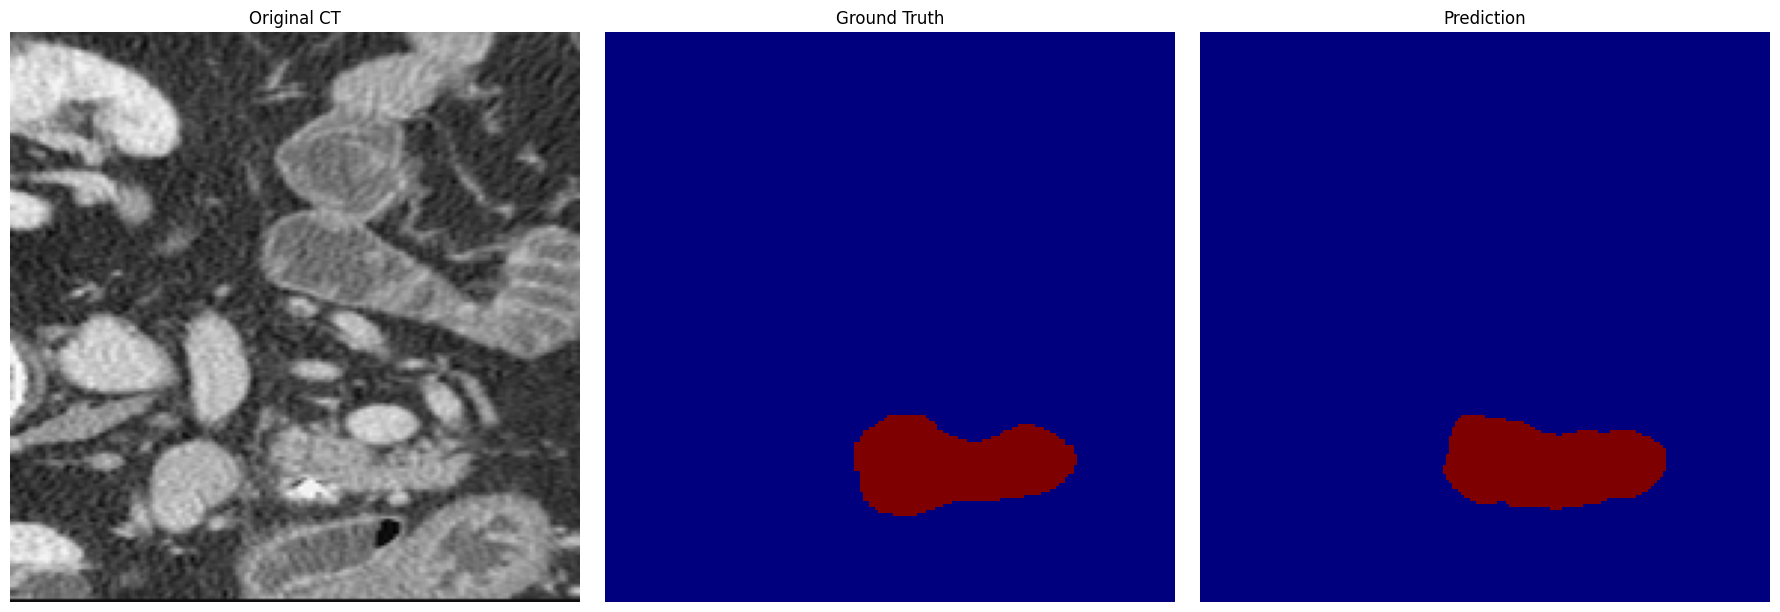

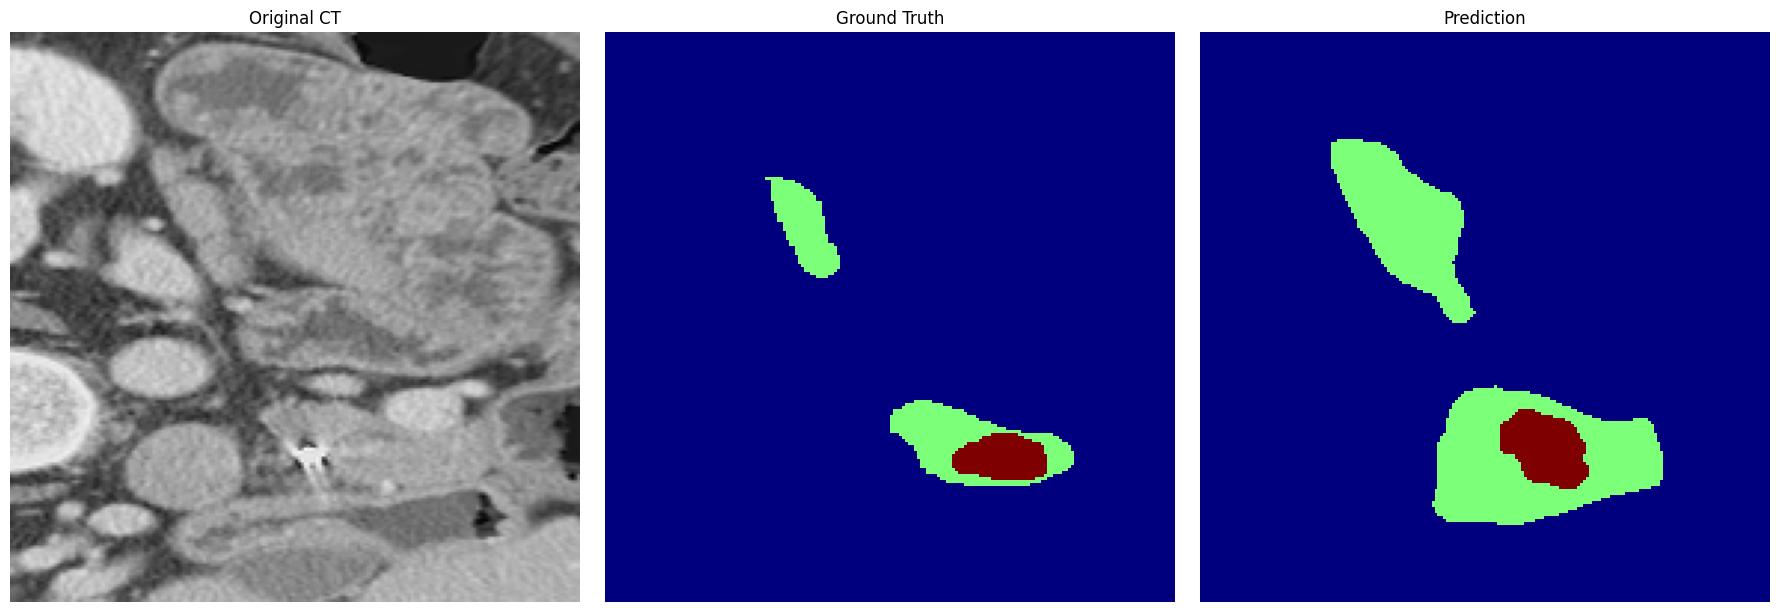

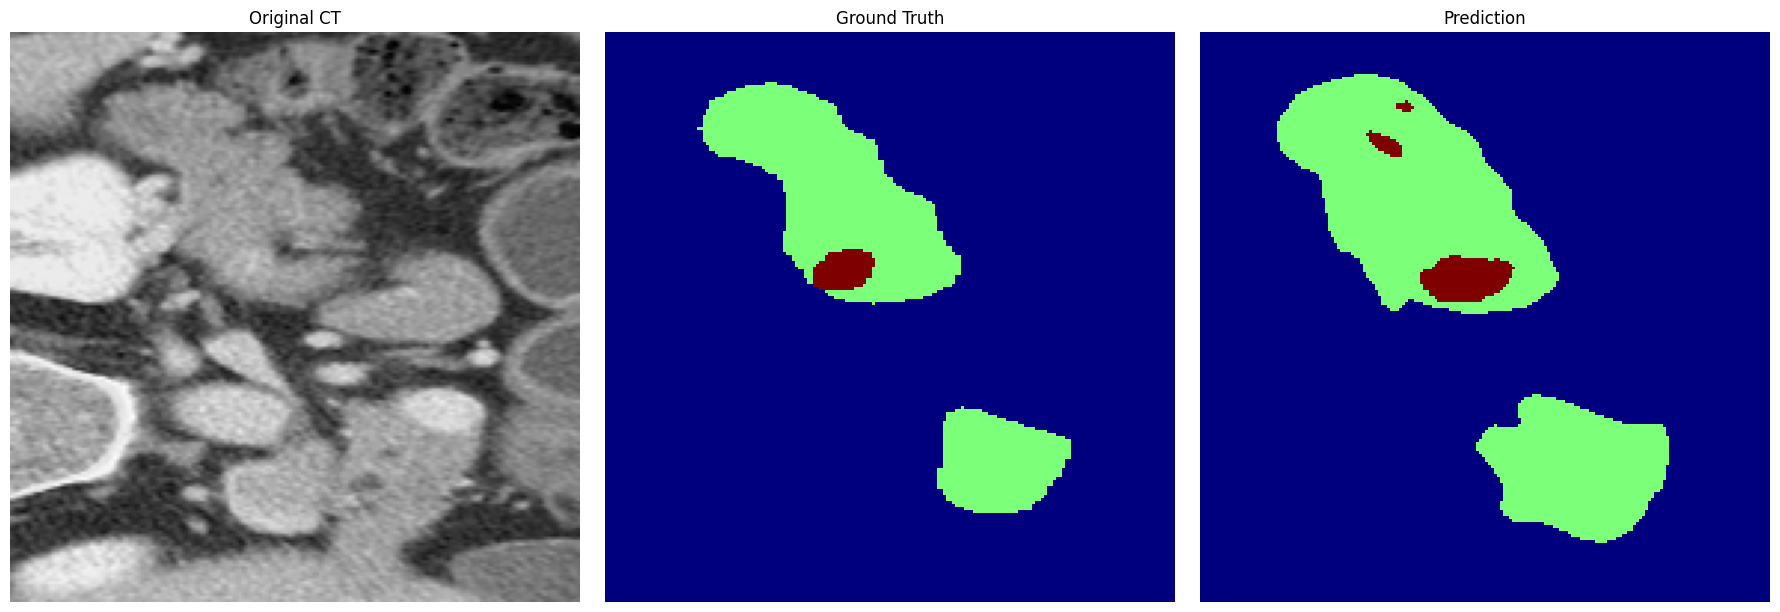

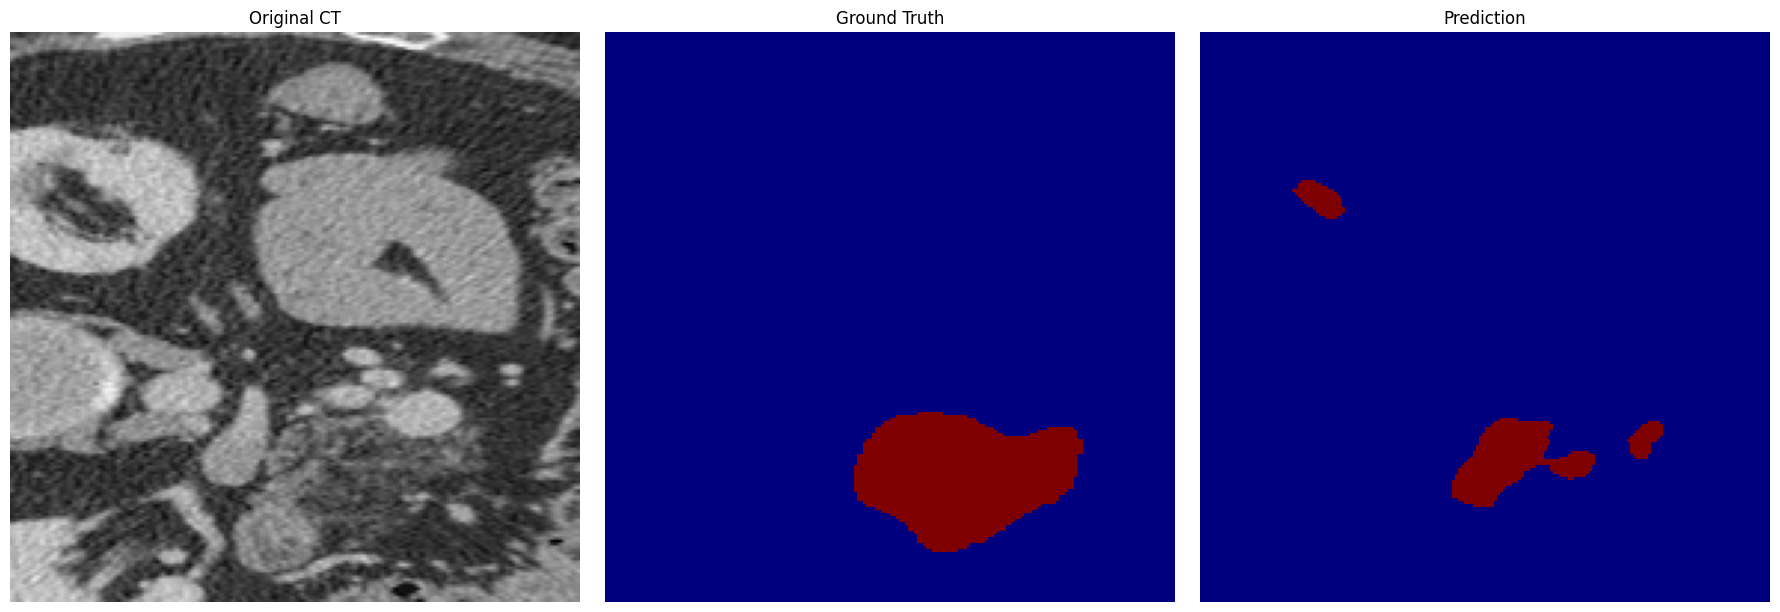

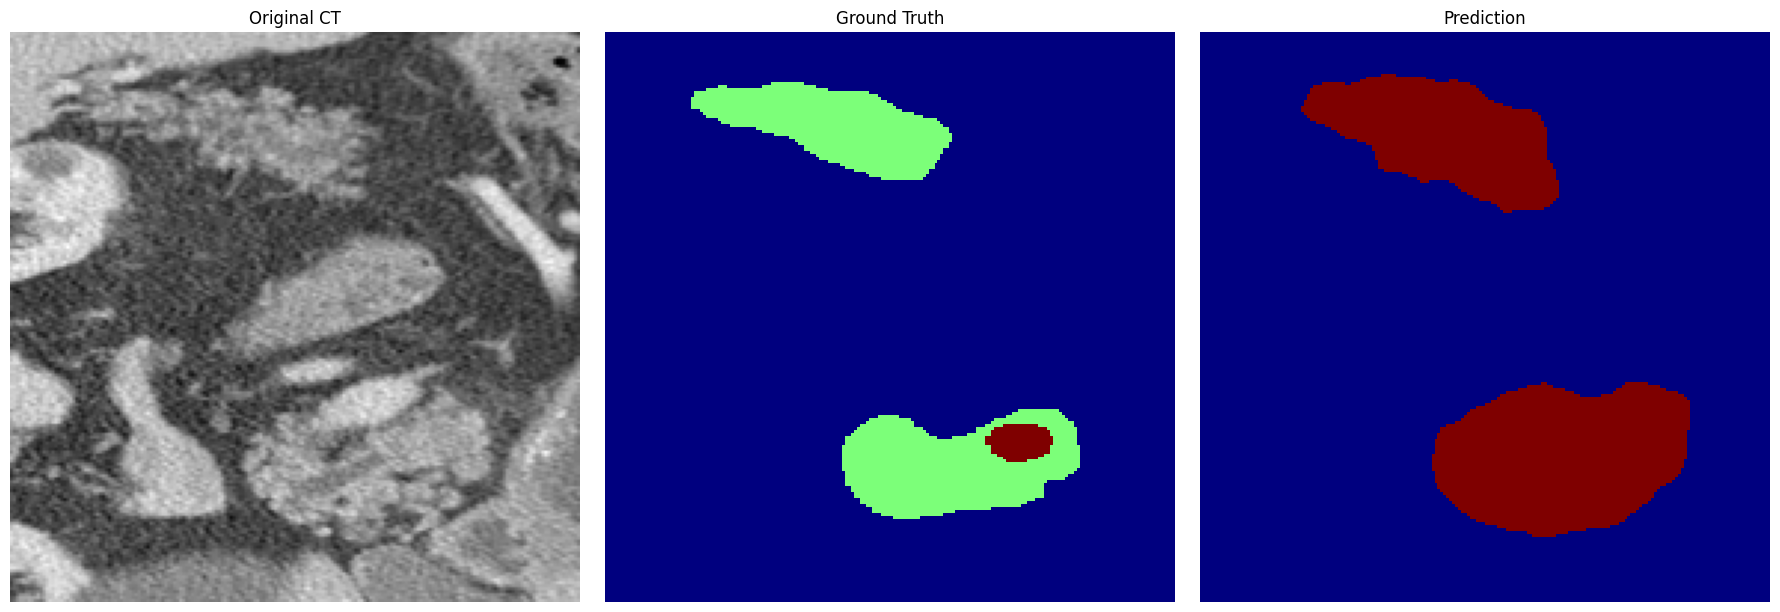

Visualization Completed


In [107]:
################################################################################
# PANTHER-Net
# PHASE 9
# SECTION 62.1
# QUALITATIVE VISUALIZATION
################################################################################

model.eval()

figure_folder = os.path.join(
    OUTPUT_DIR,
    "figures"
)

os.makedirs(
    figure_folder,
    exist_ok=True
)

num_cases = 5

for case in range(num_cases):

    image,mask = val_dataset[case]

    prediction,_ = predict_volume(
        model,
        image
    )

    image = image.squeeze().numpy()

    mask = mask.numpy()

    z = image.shape[2]//2

    plt.figure(figsize=(18,6))

    plt.subplot(131)

    plt.imshow(
        image[:,:,z],
        cmap="gray"
    )

    plt.title("Original CT")

    plt.axis("off")

    plt.subplot(132)

    plt.imshow(
        mask[:,:,z],
        cmap="jet",
        interpolation="nearest"
    )

    plt.title("Ground Truth")

    plt.axis("off")

    plt.subplot(133)

    plt.imshow(
        prediction[:,:,z],
        cmap="jet",
        interpolation="nearest"
    )

    plt.title("Prediction")

    plt.axis("off")

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            figure_folder,

            f"Prediction_{case+1}.png"

        ),

        dpi=600,

        bbox_inches="tight"

    )

    plt.show()

print("="*90)
print("Visualization Completed")
print("="*90)

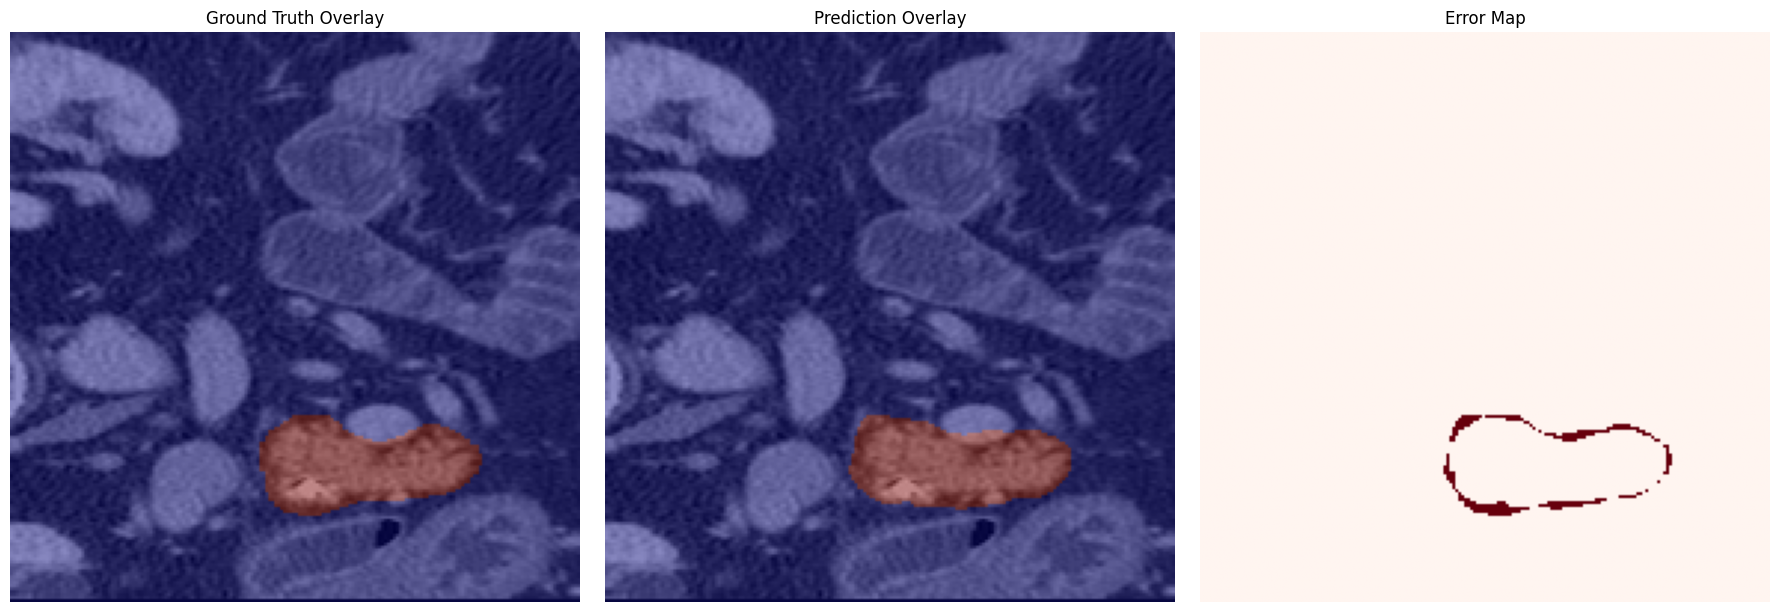

In [108]:
################################################################################
# OVERLAY VISUALIZATION
################################################################################

case = 0

image,mask = val_dataset[case]

prediction,_ = predict_volume(
    model,
    image
)

image = image.squeeze().numpy()

mask = mask.numpy()

z = image.shape[2]//2

plt.figure(figsize=(18,6))

plt.subplot(131)

plt.imshow(
    image[:,:,z],
    cmap="gray"
)

plt.imshow(
    mask[:,:,z],
    alpha=0.45,
    cmap="jet"
)

plt.title("Ground Truth Overlay")

plt.axis("off")

plt.subplot(132)

plt.imshow(
    image[:,:,z],
    cmap="gray"
)

plt.imshow(
    prediction[:,:,z],
    alpha=0.45,
    cmap="jet"
)

plt.title("Prediction Overlay")

plt.axis("off")

plt.subplot(133)

error_map = prediction[:,:,z] != mask[:,:,z]

plt.imshow(
    error_map,
    cmap="Reds"
)

plt.title("Error Map")

plt.axis("off")

plt.tight_layout()

plt.savefig(

    os.path.join(

        figure_folder,

        "Overlay_Result.png"

    ),

    dpi=600,

    bbox_inches="tight"

)

plt.show()

In [109]:
################################################################################
# SAVE COMPLETE PREDICTIONS
################################################################################

prediction_folder = os.path.join(
    OUTPUT_DIR,
    "predictions"
)

os.makedirs(
    prediction_folder,
    exist_ok=True
)

model.eval()

with torch.no_grad():

    for idx,(image,mask) in enumerate(tqdm(val_loader)):

        image = image.to(DEVICE)

        output = model(image)

        pred = torch.argmax(
            output,
            dim=1
        )

        pred = pred.squeeze().cpu().numpy()

        np.save(

            os.path.join(

                prediction_folder,

                f"Patient_{idx+1}.npy"

            ),

            pred

        )

print("="*90)
print("Predictions Saved Successfully")
print("="*90)

  0%|          | 0/57 [00:00<?, ?it/s]

Predictions Saved Successfully


In [110]:
################################################################################
# VISUALIZATION SUMMARY
################################################################################

print("="*90)

print("Figures Generated")

print()

print("Prediction_1.png")
print("Prediction_2.png")
print("Prediction_3.png")
print("Prediction_4.png")
print("Prediction_5.png")

print()

print("Overlay_Result.png")

print()

print("All predictions stored in")

print(prediction_folder)

print("="*90)

Figures Generated

Prediction_1.png
Prediction_2.png
Prediction_3.png
Prediction_4.png
Prediction_5.png

Overlay_Result.png

All predictions stored in
./PANTHER_Output/predictions


In [111]:
################################################################################
# PANTHER-Net
# PHASE 10
# SECTION 63.1
# DESCRIPTIVE STATISTICS
################################################################################

statistics_df = pd.DataFrame({

    "Metric":[
        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "Specificity"
    ],

    "Mean":[
        np.mean(all_dice),
        np.mean(all_iou),
        np.mean(all_precision),
        np.mean(all_recall),
        np.mean(all_specificity)
    ],

    "Std":[
        np.std(all_dice),
        np.std(all_iou),
        np.std(all_precision),
        np.std(all_recall),
        np.std(all_specificity)
    ],

    "Median":[
        np.median(all_dice),
        np.median(all_iou),
        np.median(all_precision),
        np.median(all_recall),
        np.median(all_specificity)
    ],

    "Minimum":[
        np.min(all_dice),
        np.min(all_iou),
        np.min(all_precision),
        np.min(all_recall),
        np.min(all_specificity)
    ],

    "Maximum":[
        np.max(all_dice),
        np.max(all_iou),
        np.max(all_precision),
        np.max(all_recall),
        np.max(all_specificity)
    ]

})

statistics_df

,Metric,Mean,Std,Median,Minimum,Maximum
0,Dice,0.376076,0.151975,0.364294,0.061295,0.744671
1,IoU,0.263247,0.124381,0.265992,0.032149,0.596390
2,Precision,0.341504,0.168770,0.307474,0.037770,0.915529
3,Recall,0.668927,0.177835,0.707470,0.187855,0.945420
4,Specificity,0.977947,0.011340,0.979472,0.942815,0.995855


In [112]:
################################################################################
# SAVE STATISTICS
################################################################################

statistics_file = os.path.join(

    OUTPUT_DIR,
    "tables"

)

os.makedirs(
    statistics_file,
    exist_ok=True
)

statistics_df.to_csv(

    os.path.join(

        statistics_file,

        "Statistical_Summary.csv"

    ),

    index=False

)

print("="*90)

print("Statistics Saved")

print("="*90)

Statistics Saved


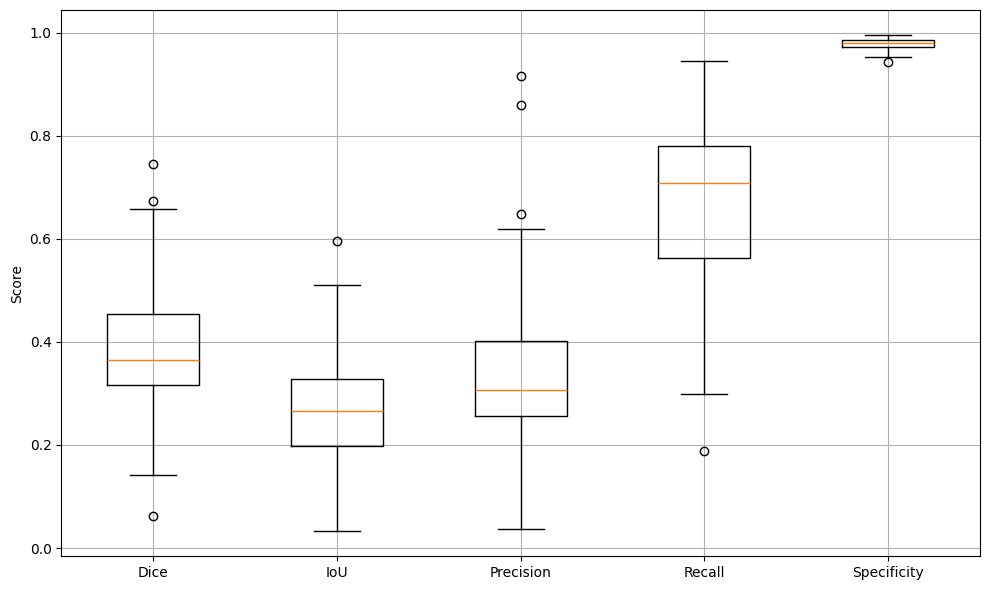

In [113]:
################################################################################
# BOXPLOT
################################################################################

plt.figure(figsize=(10,6))

plt.boxplot(

    [

        all_dice,
        all_iou,
        all_precision,
        all_recall,
        all_specificity

    ],

    labels=[

        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "Specificity"

    ]

)

plt.ylabel("Score")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(

        figure_folder,

        "Metric_Boxplot.png"

    ),

    dpi=600

)

plt.show()

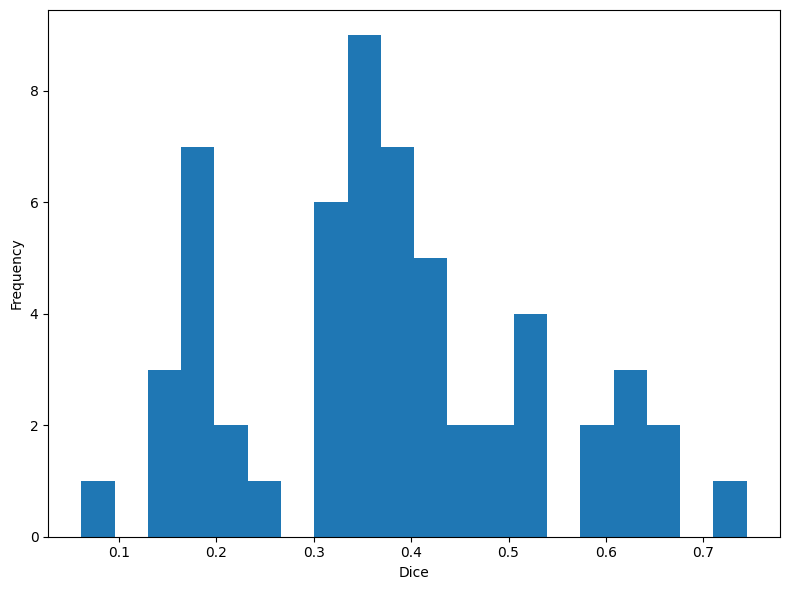

In [114]:
################################################################################
# HISTOGRAM
################################################################################

plt.figure(figsize=(8,6))

plt.hist(

    all_dice,

    bins=20

)

plt.xlabel("Dice")

plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(

    os.path.join(

        figure_folder,

        "Dice_Histogram.png"

    ),

    dpi=600

)

plt.show()

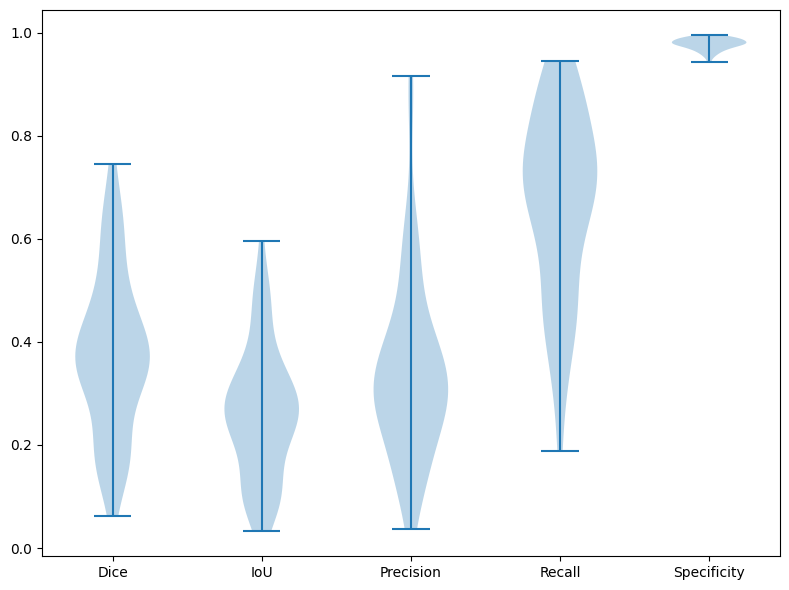

In [115]:
################################################################################
# VIOLIN PLOT
################################################################################

plt.figure(figsize=(8,6))

plt.violinplot(

    [

        all_dice,
        all_iou,
        all_precision,
        all_recall,
        all_specificity

    ]

)

plt.xticks(

    [1,2,3,4,5],

    [

        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "Specificity"

    ]

)

plt.tight_layout()

plt.savefig(

    os.path.join(

        figure_folder,

        "Metric_Violin.png"

    ),

    dpi=600

)

plt.show()

In [116]:
################################################################################
# PUBLICATION TABLE
################################################################################

publication_table = statistics_df.copy()

publication_table = publication_table.round(4)

publication_table.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "tables",

        "Publication_Table.csv"

    ),

    index=False

)

publication_table

,Metric,Mean,Std,Median,Minimum,Maximum
0,Dice,0.3761,0.1520,0.3643,0.0613,0.7447
1,IoU,0.2632,0.1244,0.2660,0.0321,0.5964
2,Precision,0.3415,0.1688,0.3075,0.0378,0.9155
3,Recall,0.6689,0.1778,0.7075,0.1879,0.9454
4,Specificity,0.9779,0.0113,0.9795,0.9428,0.9959


In [117]:
################################################################################
# PANTHER-Net
# PHASE 11
# SECTION 64.1
# MODEL INFORMATION
################################################################################

total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("="*90)
print("MODEL INFORMATION")
print("="*90)

print(f"Total Parameters      : {total_params:,}")
print(f"Trainable Parameters  : {trainable_params:,}")

print("="*90)

MODEL INFORMATION
Total Parameters      : 27,721,427
Trainable Parameters  : 27,721,427


In [118]:
################################################################################
# GPU MEMORY
################################################################################

allocated = torch.cuda.memory_allocated() / 1024**3

reserved = torch.cuda.memory_reserved() / 1024**3

print("="*90)
print("GPU MEMORY")
print("="*90)

print(f"Allocated : {allocated:.2f} GB")
print(f"Reserved  : {reserved:.2f} GB")

print("="*90)

GPU MEMORY
Allocated : 3.35 GB
Reserved  : 6.18 GB


In [119]:
################################################################################
# INFERENCE TIME
################################################################################

images, masks = next(iter(val_loader))

images = images.to(DEVICE)

torch.cuda.synchronize()

start = time.time()

with torch.no_grad():

    _ = model(images)

torch.cuda.synchronize()

end = time.time()

inference_time = end - start

print("="*90)

print("Inference Time")

print("="*90)

print(f"{inference_time:.4f} seconds")

print("="*90)

Inference Time
0.9830 seconds


In [120]:
################################################################################
# FPS
################################################################################

fps = 1.0 / inference_time

print("="*90)

print(f"FPS : {fps:.2f}")

print("="*90)

FPS : 1.02


In [121]:
################################################################################
# COMPUTATIONAL COMPLEXITY TABLE
################################################################################

complexity = pd.DataFrame({

    "Metric":[

        "Total Parameters",
        "Trainable Parameters",
        "GPU Allocated (GB)",
        "GPU Reserved (GB)",
        "Inference Time (s)",
        "FPS"

    ],

    "Value":[

        total_params,
        trainable_params,
        allocated,
        reserved,
        inference_time,
        fps

    ]

})

complexity

,Metric,Value
0,Total Parameters,2.772143e+07
1,Trainable Parameters,2.772143e+07
2,GPU Allocated (GB),3.348581e+00
3,GPU Reserved (GB),6.183594e+00
4,Inference Time (s),9.829540e-01
5,FPS,1.017342e+00


In [122]:
################################################################################
# SAVE COMPLEXITY
################################################################################

complexity.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "tables",

        "Computational_Complexity.csv"

    ),

    index=False

)

print("="*90)

print("Computational Complexity Saved")

print("="*90)

Computational Complexity Saved


In [123]:
################################################################################
# ZIP COMPLETE OUTPUT
################################################################################

import shutil

zip_path = shutil.make_archive(

    "PANTHER_Output_Final",

    "zip",

    OUTPUT_DIR

)

print("="*90)

print("ZIP Created Successfully")

print(zip_path)

print("="*90)

ZIP Created Successfully
/kaggle/working/PANTHER_Output_Final.zip


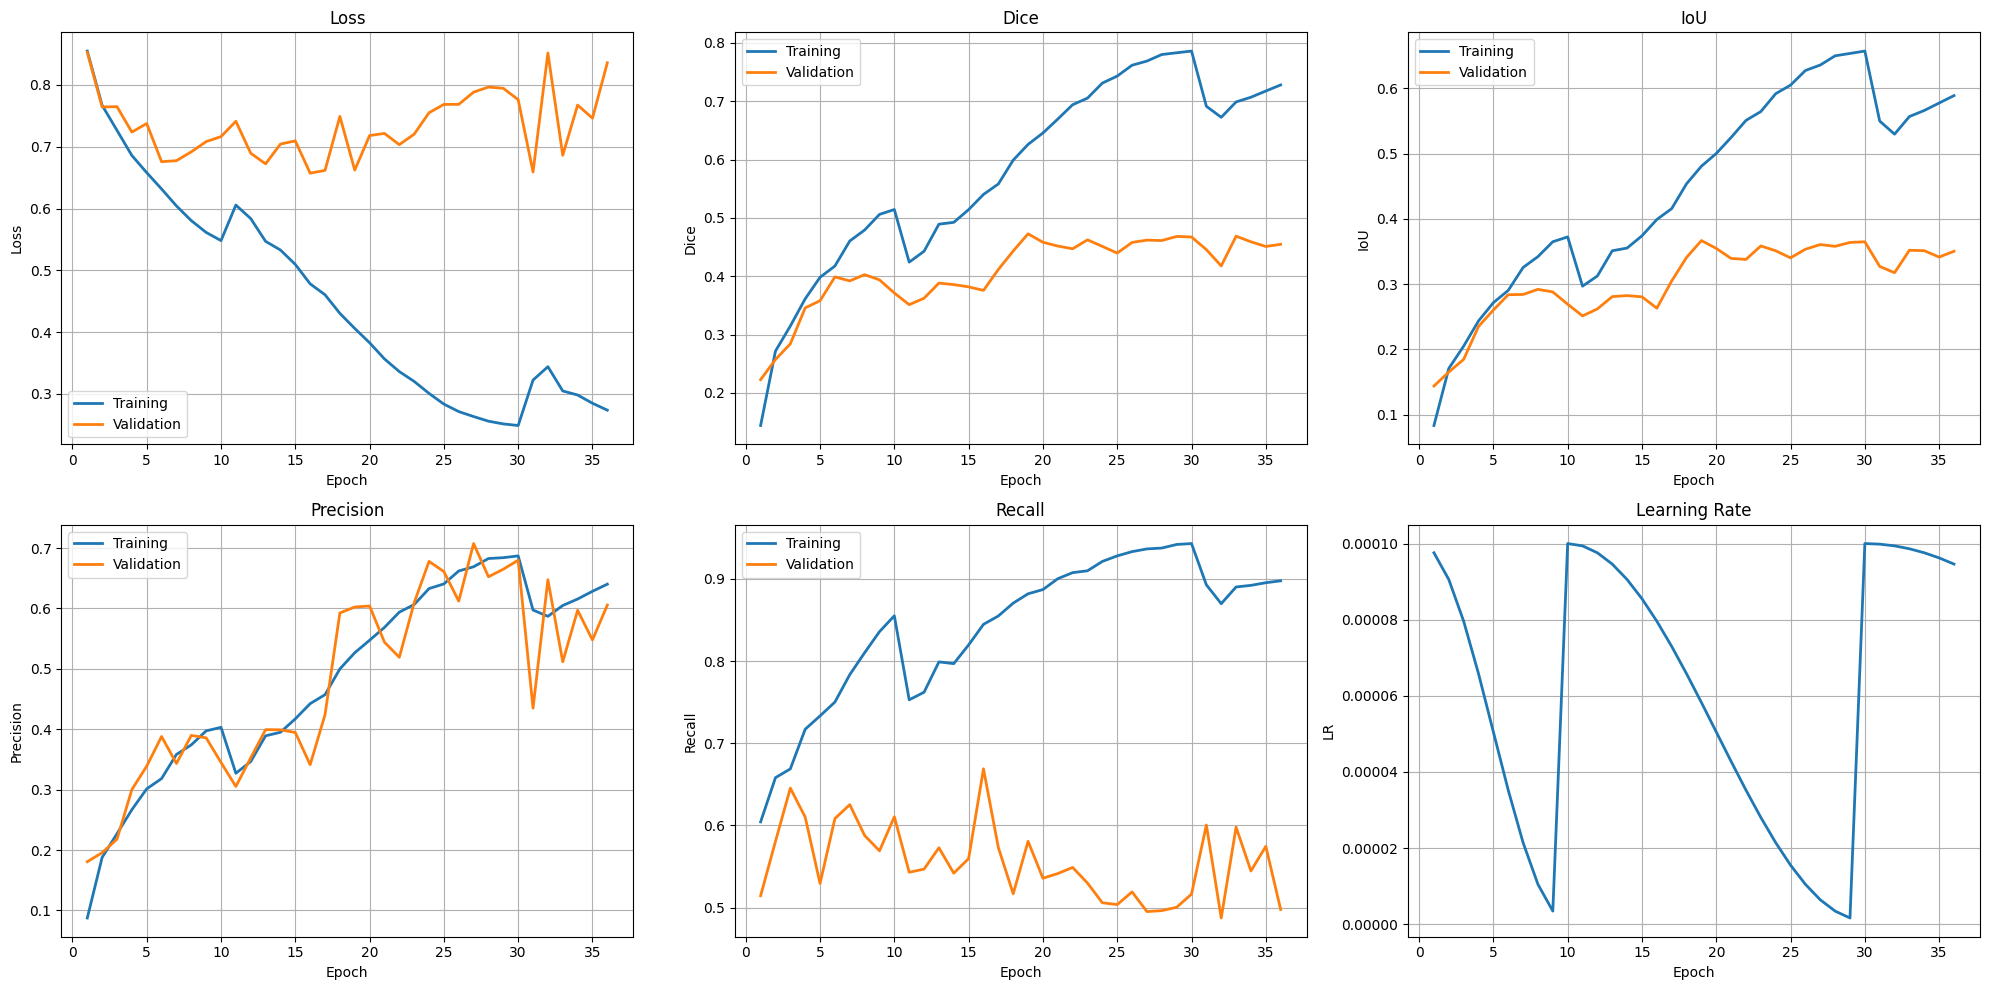

Training Curves Saved
./PANTHER_Output/figures/Training_Curves_36_Epochs.png


In [124]:
################################################################################
# PANTHER-Net
# FINAL TRAINING CURVES
################################################################################

import pandas as pd
import matplotlib.pyplot as plt
import os

history_file = os.path.join(
    OUTPUT_DIR,
    "history",
    "training_history.csv"
)

# If history exists in memory, use it; otherwise read the CSV
if os.path.exists(history_file):
    history_df = pd.read_csv(history_file)
else:
    history_df = pd.DataFrame(history)

# -------------------------------------------------------------------------
# Standardize column names (supports different notebook versions)
# -------------------------------------------------------------------------

history_df.columns = [c.lower() for c in history_df.columns]

epochs = range(1, len(history_df) + 1)

# -------------------------------------------------------------------------
# Create Figure
# -------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# ---------------- Loss ----------------

axes[0,0].plot(
    epochs,
    history_df["train_loss"],
    linewidth=2,
    label="Training"
)

axes[0,0].plot(
    epochs,
    history_df["val_loss"],
    linewidth=2,
    label="Validation"
)

axes[0,0].set_title("Loss")
axes[0,0].set_xlabel("Epoch")
axes[0,0].set_ylabel("Loss")
axes[0,0].grid(True)
axes[0,0].legend()

# ---------------- Dice ----------------

axes[0,1].plot(
    epochs,
    history_df["train_dice"],
    linewidth=2,
    label="Training"
)

axes[0,1].plot(
    epochs,
    history_df["val_dice"],
    linewidth=2,
    label="Validation"
)

axes[0,1].set_title("Dice")
axes[0,1].set_xlabel("Epoch")
axes[0,1].set_ylabel("Dice")
axes[0,1].grid(True)
axes[0,1].legend()

# ---------------- IoU ----------------

axes[0,2].plot(
    epochs,
    history_df["train_iou"],
    linewidth=2,
    label="Training"
)

axes[0,2].plot(
    epochs,
    history_df["val_iou"],
    linewidth=2,
    label="Validation"
)

axes[0,2].set_title("IoU")
axes[0,2].set_xlabel("Epoch")
axes[0,2].set_ylabel("IoU")
axes[0,2].grid(True)
axes[0,2].legend()

# ---------------- Precision ----------------

axes[1,0].plot(
    epochs,
    history_df["train_precision"],
    linewidth=2,
    label="Training"
)

axes[1,0].plot(
    epochs,
    history_df["val_precision"],
    linewidth=2,
    label="Validation"
)

axes[1,0].set_title("Precision")
axes[1,0].set_xlabel("Epoch")
axes[1,0].set_ylabel("Precision")
axes[1,0].grid(True)
axes[1,0].legend()

# ---------------- Recall ----------------

axes[1,1].plot(
    epochs,
    history_df["train_recall"],
    linewidth=2,
    label="Training"
)

axes[1,1].plot(
    epochs,
    history_df["val_recall"],
    linewidth=2,
    label="Validation"
)

axes[1,1].set_title("Recall")
axes[1,1].set_xlabel("Epoch")
axes[1,1].set_ylabel("Recall")
axes[1,1].grid(True)
axes[1,1].legend()

# ---------------- Learning Rate ----------------

axes[1,2].plot(
    epochs,
    history_df["learning_rate"],
    linewidth=2
)

axes[1,2].set_title("Learning Rate")
axes[1,2].set_xlabel("Epoch")
axes[1,2].set_ylabel("LR")
axes[1,2].grid(True)

plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "Training_Curves_36_Epochs.png"
)

plt.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("="*90)
print("Training Curves Saved")
print(save_path)
print("="*90)

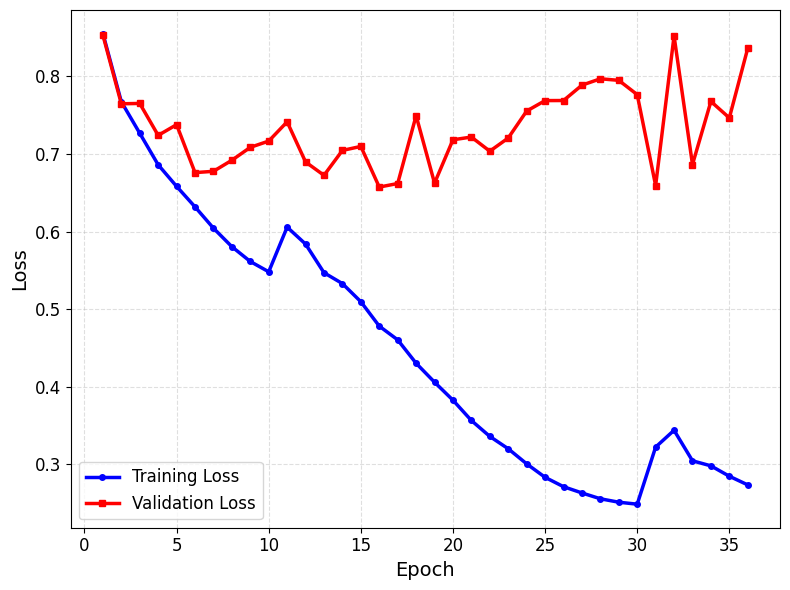

In [125]:
################################################################################
# PANTHER-Net
# PUBLICATION FIGURE
# TRAINING & VALIDATION LOSS
################################################################################

history_df = pd.read_csv(
    os.path.join(
        HISTORY_DIR,
        "training_history.csv"
    )
)

epochs = history_df["epoch"]

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    history_df["train_loss"],
    color="blue",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Training Loss"
)

plt.plot(
    epochs,
    history_df["val_loss"],
    color="red",
    linewidth=2.5,
    marker="s",
    markersize=4,
    label="Validation Loss"
)

plt.xlabel("Epoch",fontsize=14)
plt.ylabel("Loss",fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True,linestyle="--",alpha=0.4)

plt.legend(fontsize=12)

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "Figure_Training_Loss.png"

    ),

    dpi=600

)

plt.show()

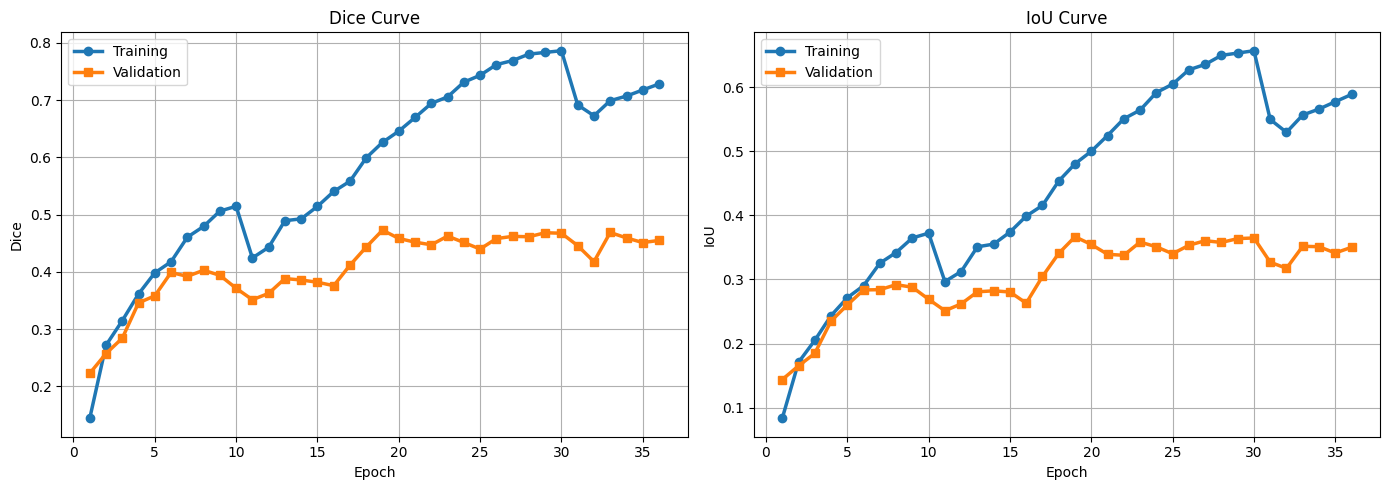

In [126]:
################################################################################
# DICE & IoU
################################################################################

fig,ax=plt.subplots(1,2,figsize=(14,5))

# Dice

ax[0].plot(

    epochs,

    history_df["train_dice"],

    linewidth=2.5,

    marker="o",

    label="Training"

)

ax[0].plot(

    epochs,

    history_df["val_dice"],

    linewidth=2.5,

    marker="s",

    label="Validation"

)

ax[0].set_xlabel("Epoch")

ax[0].set_ylabel("Dice")

ax[0].grid(True)

ax[0].legend()

ax[0].set_title("Dice Curve")

# IoU

ax[1].plot(

    epochs,

    history_df["train_iou"],

    linewidth=2.5,

    marker="o",

    label="Training"

)

ax[1].plot(

    epochs,

    history_df["val_iou"],

    linewidth=2.5,

    marker="s",

    label="Validation"

)

ax[1].set_xlabel("Epoch")

ax[1].set_ylabel("IoU")

ax[1].grid(True)

ax[1].legend()

ax[1].set_title("IoU Curve")

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "Figure_Dice_IoU.png"

    ),

    dpi=600

)

plt.show()

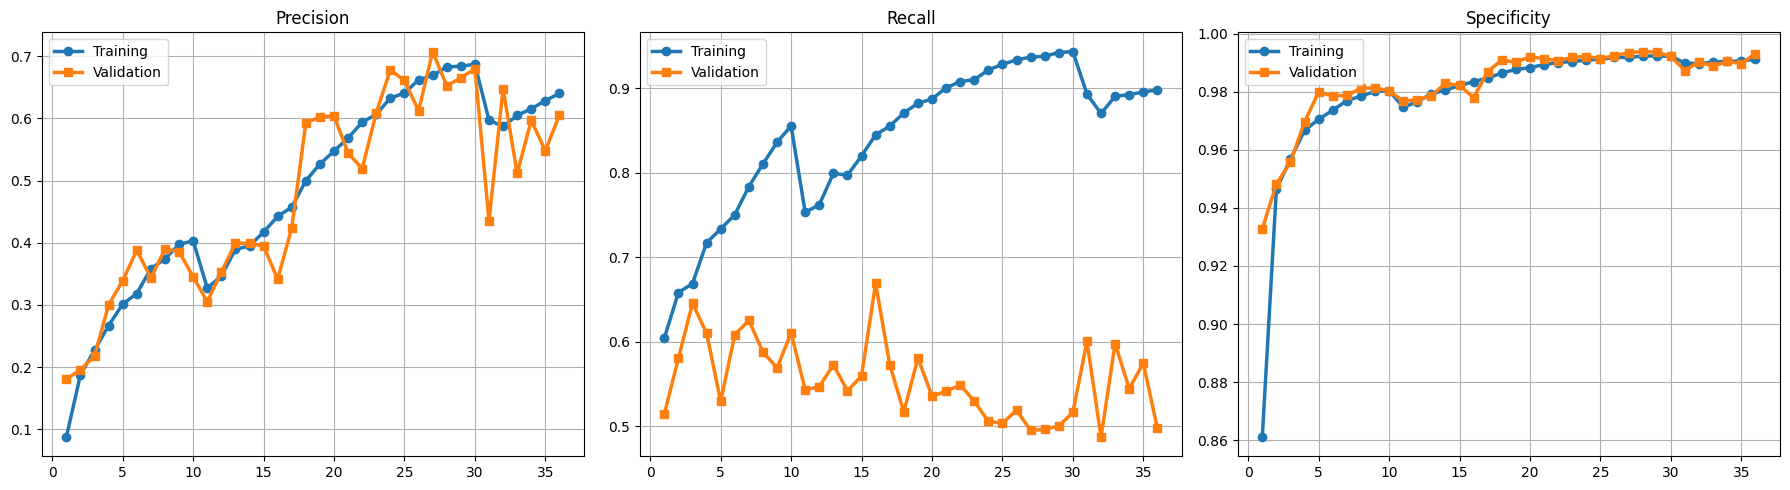

In [127]:
################################################################################
# PRECISION
# RECALL
# SPECIFICITY
################################################################################

fig,ax=plt.subplots(1,3,figsize=(18,5))

# Precision

ax[0].plot(

    epochs,

    history_df["train_precision"],

    linewidth=2.5,

    marker="o",

    label="Training"

)

ax[0].plot(

    epochs,

    history_df["val_precision"],

    linewidth=2.5,

    marker="s",

    label="Validation"

)

ax[0].set_title("Precision")

ax[0].grid(True)

ax[0].legend()

# Recall

ax[1].plot(

    epochs,

    history_df["train_recall"],

    linewidth=2.5,

    marker="o",

    label="Training"

)

ax[1].plot(

    epochs,

    history_df["val_recall"],

    linewidth=2.5,

    marker="s",

    label="Validation"

)

ax[1].set_title("Recall")

ax[1].grid(True)

ax[1].legend()

# Specificity

ax[2].plot(

    epochs,

    history_df["train_specificity"],

    linewidth=2.5,

    marker="o",

    label="Training"

)

ax[2].plot(

    epochs,

    history_df["val_specificity"],

    linewidth=2.5,

    marker="s",

    label="Validation"

)

ax[2].set_title("Specificity")

ax[2].grid(True)

ax[2].legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "Figure_Precision_Recall_Specificity.png"

    ),

    dpi=600

)

plt.show()

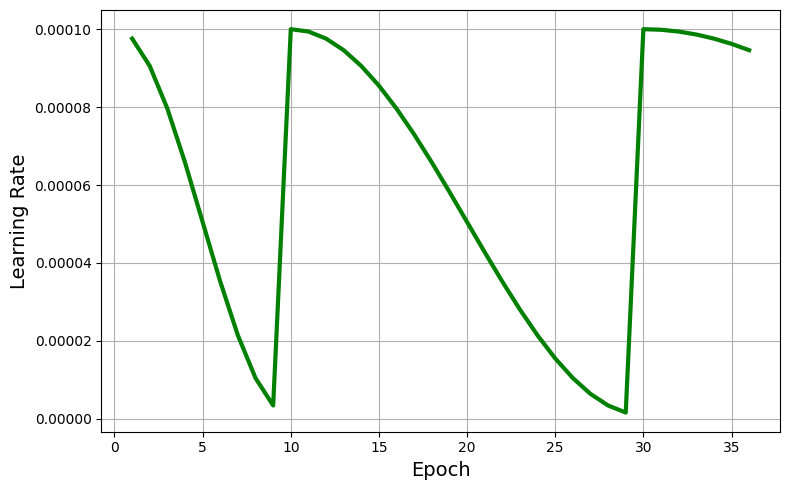

In [128]:
################################################################################
# LEARNING RATE
################################################################################

plt.figure(figsize=(8,5))

plt.plot(

    epochs,

    history_df["learning_rate"],

    linewidth=3,

    color="green"

)

plt.xlabel("Epoch",fontsize=14)

plt.ylabel("Learning Rate",fontsize=14)

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "Figure_Learning_Rate.png"

    ),

    dpi=600

)

plt.show()

In [129]:
################################################################################
# PANTHER-Net
# PUBLICATION FIGURES
# (Single Block)
################################################################################

import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt

# =============================================================================
# Create Folder
# =============================================================================

PUBLICATION_DIR = os.path.join(
    OUTPUT_DIR,
    "Publication_Figures"
)

os.makedirs(PUBLICATION_DIR, exist_ok=True)

# =============================================================================
# Load History
# =============================================================================

history_path = os.path.join(
    HISTORY_DIR,
    "training_history.csv"
)

if os.path.exists(history_path):
    history_df = pd.read_csv(history_path)
else:
    history_df = pd.DataFrame(history)

history_df.columns = [c.lower() for c in history_df.columns]

epochs = history_df["epoch"]

# =============================================================================
# Helper Function
# =============================================================================

def save_plot(
    x,
    y_list,
    labels,
    ylabel,
    filename,
    markers=None
):

    plt.figure(figsize=(8,6))

    if markers is None:
        markers = ['o'] * len(y_list)

    for y,label,m in zip(y_list,labels,markers):

        plt.plot(
            x,
            y,
            linewidth=3,
            marker=m,
            markersize=5,
            label=label
        )

    plt.xlabel("Epoch",fontsize=14)
    plt.ylabel(ylabel,fontsize=14)

    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    plt.grid(True,linestyle="--",alpha=0.4)

    if len(labels)>1:
        plt.legend(fontsize=12)

    plt.tight_layout()

    plt.savefig(
        os.path.join(PUBLICATION_DIR,filename),
        dpi=600,
        bbox_inches="tight"
    )

    plt.close()

# =============================================================================
# Training Loss
# =============================================================================

save_plot(

    epochs,

    [history_df["train_loss"]],

    ["Training"],

    "Training Loss",

    "Figure_01_Training_Loss.png"

)

# =============================================================================
# Validation Loss
# =============================================================================

save_plot(

    epochs,

    [history_df["val_loss"]],

    ["Validation"],

    "Validation Loss",

    "Figure_02_Validation_Loss.png"

)

# =============================================================================
# Dice
# =============================================================================

save_plot(

    epochs,

    [

        history_df["train_dice"],
        history_df["val_dice"]

    ],

    [

        "Training",
        "Validation"

    ],

    "Dice Score",

    "Figure_03_Dice.png",

    ['o','s']

)

# =============================================================================
# IoU
# =============================================================================

save_plot(

    epochs,

    [

        history_df["train_iou"],
        history_df["val_iou"]

    ],

    [

        "Training",
        "Validation"

    ],

    "IoU",

    "Figure_04_IoU.png",

    ['o','s']

)

# =============================================================================
# Precision
# =============================================================================

save_plot(

    epochs,

    [

        history_df["train_precision"],
        history_df["val_precision"]

    ],

    [

        "Training",
        "Validation"

    ],

    "Precision",

    "Figure_05_Precision.png",

    ['o','s']

)

# =============================================================================
# Recall
# =============================================================================

save_plot(

    epochs,

    [

        history_df["train_recall"],
        history_df["val_recall"]

    ],

    [

        "Training",
        "Validation"

    ],

    "Recall",

    "Figure_06_Recall.png",

    ['o','s']

)

# =============================================================================
# Specificity
# =============================================================================

save_plot(

    epochs,

    [

        history_df["train_specificity"],
        history_df["val_specificity"]

    ],

    [

        "Training",
        "Validation"

    ],

    "Specificity",

    "Figure_07_Specificity.png",

    ['o','s']

)

# =============================================================================
# Learning Rate
# =============================================================================

save_plot(

    epochs,

    [

        history_df["learning_rate"]

    ],

    [

        "Learning Rate"

    ],

    "Learning Rate",

    "Figure_08_Learning_Rate.png"

)

# =============================================================================
# ZIP Folder
# =============================================================================

zip_file = shutil.make_archive(

    os.path.join(
        OUTPUT_DIR,
        "Publication_Figures"
    ),

    "zip",

    PUBLICATION_DIR

)

# =============================================================================
# Summary
# =============================================================================

print("="*90)
print("Publication Figures Generated Successfully")
print("="*90)

print()

print("Folder :")
print(PUBLICATION_DIR)

print()

print("ZIP File :")
print(zip_file)

print()

print("Generated Figures")

for file in sorted(os.listdir(PUBLICATION_DIR)):
    print("✓",file)

print("="*90)

Publication Figures Generated Successfully

Folder :
./PANTHER_Output/Publication_Figures

ZIP File :
/kaggle/working/PANTHER_Output/Publication_Figures.zip

Generated Figures
✓ Figure_01_Training_Loss.png
✓ Figure_02_Validation_Loss.png
✓ Figure_03_Dice.png
✓ Figure_04_IoU.png
✓ Figure_05_Precision.png
✓ Figure_06_Recall.png
✓ Figure_07_Specificity.png
✓ Figure_08_Learning_Rate.png
